<a href="https://colab.research.google.com/github/francisdick/detecteur-langue-fon/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SEANCE 1 : charger, observer, nettoyer**

Cellule 1 : connexion au Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DOSSIER = "/content/drive/MyDrive/FRANCIS DICK CLAUDE IA/Projet NLP - Détecteur de Langue Fon/"
print(os.listdir(DOSSIER))

Mounted at /content/drive
['Présentation du projet - Détecteur de langue Fon, Français, Anglais.gdoc', '00_bases_python.ipynb', 'fon_300_avec_traduction.csv', 'fon_300_avec_traduction.gsheet', 'fon_zenodo_300.csv', 'fon_zenodo_300 (1).gsheet', 'fon_zenodo_300.gsheet', 'fra_sentences.tsv.bz2', 'eng_sentences.tsv.bz2', 'a_relire_fr (1).gsheet', 'Bon de vérification - Tatoeba FR EN.gsheet', 'a_relire_fr.gsheet', 'a_relire_en.gsheet', 'a_relire_fr.csv', 'a_relire_en.csv', 'tatoeba_fr_300.csv', 'tatoeba_en_300.csv', 'phrases.csv', 'pieges.csv', 'SOURCES.md', 'phrases.gsheet', '01_collecte_avant_github', '01_collecte']


Cellule 2 : chargement

In [2]:
import pandas as pd

df = pd.read_csv(DOSSIER + "phrases.csv", encoding="utf-8")
pieges = pd.read_csv(DOSSIER + "pieges.csv", encoding="utf-8")

print("Taille :", df.shape)   # (lignes, colonnes) → attendu (900, 3)
df.head(10)

Taille : (900, 3)


,texte,langue,source
0,wanyiyi kpede si hun wa nyanya a,fon,zenodo_4432712_simplifie
1,Not a star was to be seen in the sky.,en,tatoeba_18317
2,a do folo n'e we,fon,zenodo_4432712_simplifie
3,"Quoi que tu dises, mon pote.",fr,tatoeba_2164847
4,mɛ e nɔ sí wɛ̀,fon,zenodo_4432712
5,Give me a shawarma and a diet cola.,en,tatoeba_2915020
6,a ka na jlá ɖó bó sɔ́ jó n'í,fon,zenodo_4432712
7,ɖò hweɖelɛ́ nú ɔ́ nù ɖé lɛ́ nɔ́ wá bú do dó gb...,fon,zenodo_4432712
8,e nɔ ɖu lan a,fon,zenodo_4432712
9,un hen na mo un de du a,fon,zenodo_4432712_simplifie


Cellule 3 : vue d’ensemble

In [3]:
df.info()                         # types des colonnes et valeurs manquantes
print()
print(df["langue"].value_counts())
print()
print(df["source"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   texte   900 non-null    object
 1   langue  900 non-null    object
 2   source  900 non-null    object
dtypes: object(3)
memory usage: 21.2+ KB

langue
fon    300
en     300
fr     300
Name: count, dtype: int64

source
zenodo_4432712_simplifie    150
zenodo_4432712              150
tatoeba_264893                1
tatoeba_3168234               1
tatoeba_12467702              1
                           ... 
tatoeba_1818919               1
tatoeba_5653894               1
tatoeba_1858380               1
tatoeba_388529                1
tatoeba_53888                 1
Name: count, Length: 602, dtype: int64


Cellule 4 : nettoyage, en comptant ce qu’on retire

In [4]:
import unicodedata

avant = len(df)

# 1. Lignes vides (à faire en premier : les fonctions de texte plantent sur une case vide)
df = df.dropna(subset=["texte", "langue"])

# 2. Espaces en trop : au début, à la fin, et les doubles espaces au milieu
df["texte"] = df["texte"].str.strip().str.replace(r"\s+", " ", regex=True)

# 3. On retire les phrases devenues vides
df = df[df["texte"] != ""]

# 4. Normalisation Unicode (déjà faite en phase 1, ici c'est une sécurité)
df["texte"] = df["texte"].apply(lambda t: unicodedata.normalize("NFC", t))

print("Lignes retirées :", avant - len(df))

Lignes retirées : 0


Cellule 5 : les doublons, à regarder avant de les supprimer

In [5]:
# keep=False : affiche TOUTES les copies, pas seulement la deuxième
doublons = df[df.duplicated(subset="texte", keep=False)]
print("Lignes en double :", len(doublons))

# Cas grave : même phrase, mais deux langues différentes
conflits = doublons.groupby("texte")["langue"].nunique()
print("Phrases avec deux étiquettes différentes :", (conflits > 1).sum())

doublons.sort_values("texte")

Lignes en double : 0
Phrases avec deux étiquettes différentes : 0


,texte,langue,source


Cellule 6 : suppression des doublons

In [6]:
avant = len(df)

# On compare en minuscules pour attraper "Bonjour." et "bonjour."
df["cle"] = df["texte"].str.lower()
df = df.drop_duplicates(subset="cle").drop(columns="cle")

print("Doublons retirés :", avant - len(df))
print(df["langue"].value_counts())

Doublons retirés : 0
langue
fon    300
en     300
fr     300
Name: count, dtype: int64


# **SEANCE 2 : explorer en profondeur et sauvegarder**

Cellule 7 : longueur des phrases par langue

In [7]:
df["longueur"] = df["texte"].str.len()               # nombre de caractères
df["nb_mots"] = df["texte"].str.split().str.len()    # nombre de mots

df.groupby("langue")[["longueur", "nb_mots"]].agg(["mean", "median", "min", "max"]).round(1)

longueur                 nb_mots               
           mean median min  max    mean median min max
langue                                                
en         37.4   33.0   7  145     7.3    7.0   2  24
fon        20.1   17.0   4  102     5.6    5.0   2  25
fr         38.8   34.0  11  146     7.1    6.0   2  25

Cellule 8 : le même résultat sous forme de graphique

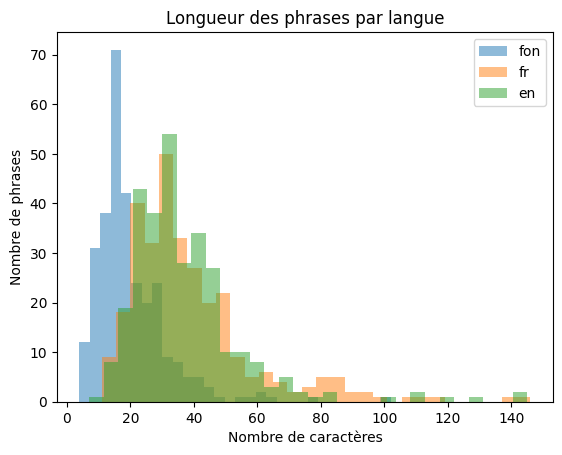

In [8]:
import matplotlib.pyplot as plt

for langue in ["fon", "fr", "en"]:
    plt.hist(df[df["langue"] == langue]["longueur"], bins=30, alpha=0.5, label=langue)

plt.xlabel("Nombre de caractères")
plt.ylabel("Nombre de phrases")
plt.title("Longueur des phrases par langue")
plt.legend()
plt.show()

Cellule 9 : les lettres spéciales du fon

In [9]:
SPECIAUX = "ɔɛɖƆƐƉ"
df["a_speciaux"] = df["texte"].apply(lambda t: any(c in SPECIAUX for c in t))

pd.crosstab(df["langue"], df["a_speciaux"])

a_speciaux,False,True
langue,,
en,300,0
fon,170,130
fr,300,0


Cellule 10 : les caractères propres à chaque langue

In [10]:
caracteres = {l: set("".join(df[df["langue"] == l]["texte"])) for l in ["fon", "fr", "en"]}

print("Seulement en fon :", sorted(caracteres["fon"] - caracteres["fr"] - caracteres["en"]))
print("Seulement en fr  :", sorted(caracteres["fr"] - caracteres["fon"] - caracteres["en"]))
print("Seulement en en  :", sorted(caracteres["en"] - caracteres["fon"] - caracteres["fr"]))

# Contrôle de la correction faite en phase 1
SUSPECTS = ["ε", "ð", "Ð"]
for s in SUSPECTS:
    n = df["texte"].str.contains(s, regex=False).sum()
    print(f"'{s}' (U+{ord(s):04X}) : {n} phrase(s)")

Seulement en fon : ['á', 'ì', 'í', 'ò', 'ó', 'ú', 'ă', 'ĕ', 'ĭ', 'ŏ', 'ŭ', 'ǔ', 'ɔ', 'ɖ', 'ɛ', '̀', '́', '̆']
Seulement en fr  : ['9', 'Q', 'U', 'Ç', 'É', 'â', 'ç', 'ê', 'ë', 'î', 'ï', 'ô', 'û', 'œ']
Seulement en en  : ['"', '$', '0', '2', '3', '5', ':', 'H', 'K', 'W']
'ε' (U+03B5) : 0 phrase(s)
'ð' (U+00F0) : 0 phrase(s)
'Ð' (U+00D0) : 0 phrase(s)


Cellule 11 : fuite vers les phrases pièges

In [11]:
textes_pieges = set(pieges["texte"].str.strip())
communes = df[df["texte"].isin(textes_pieges)]

print("Phrases pièges présentes aussi dans le jeu principal :", len(communes))
communes

Phrases pièges présentes aussi dans le jeu principal : 0


,texte,langue,source,longueur,nb_mots,a_speciaux


Cellule 12 : équilibre des classes

In [12]:
comptes = df["langue"].value_counts()
print(comptes)

ecart = comptes.max() - comptes.min()
print("Écart :", ecart)

if ecart > 0:
    n_min = comptes.min()
    df = df.groupby("langue").sample(n=n_min, random_state=42)
    print("Après équilibrage :")
    print(df["langue"].value_counts())

langue
fon    300
en     300
fr     300
Name: count, dtype: int64
Écart : 0


Cellule 13 : sauvegarde et vérification

In [13]:
# On ne garde que les colonnes d'origine : longueur, a_speciaux, etc. se recalculent
# et ne doivent pas être fournies au modèle
COLONNES = ["texte", "langue", "source"]
df[COLONNES].to_csv(DOSSIER + "phrases_propres.csv", index=False, encoding="utf-8")

# Vérification : on relit le fichier depuis le disque
verif = pd.read_csv(DOSSIER + "phrases_propres.csv", encoding="utf-8")
print(verif.shape)
print(verif["langue"].value_counts())
verif.sample(5, random_state=0)

(900, 3)
langue
fon    300
en     300
fr     300
Name: count, dtype: int64


,texte,langue,source
492,Les as-tu googlées ?,fr,tatoeba_10524560
141,étɛ́ mɛ̀ a ma mɔ̀ nù jɛ́ ă,fon,zenodo_4432712
409,He is only forty.,en,tatoeba_8409497
31,Tom has a talent for writing.,en,tatoeba_3724040
570,La récompense devrait m’en être attribuée !,fr,tatoeba_8132198


In [14]:
# Cellule 13 bis : contrôles supplémentaires (biais de forme)
import unicodedata

controle = df.groupby("langue")["texte"].agg(
    maj_debut=lambda s: round(s.str[0].str.isupper().mean() * 100),
    ponct_fin=lambda s: round(s.str[-1].isin(list(".!?")).mean() * 100),
    moins_15_car=lambda s: (s.str.len() < 15).sum(),
)
print(controle, "\n")

# Tons montants : brève (U+0306) ou caron (U+030C) ?
nfd = df["texte"].apply(lambda t: unicodedata.normalize("NFD", t))
print("Brève :", nfd.str.contains("\u0306").sum(), "| Caron :", nfd.str.contains("\u030C").sum())

        maj_debut  ponct_fin  moins_15_car
langue                                    
en             99         99             5
fon             0          0            97
fr            100        100             6 

Brève : 23 | Caron : 1


Cellule 14 : ton journal d’exploration (cellule texte)

## Ce que j'ai appris sur mes données

**Bilan du nettoyage**
- Nombre final de phrases : 900 (fon 300 / fr 300 / en 300), classes parfaitement équilibrées
- Lignes vides : 0 · Doublons : 0 (dont conflits d'étiquette : 0)
- Caractères suspects restants (ε, ð, Ð) : 0 → correction de la phase 1 confirmée
- Fuite vers pieges.csv : 0 phrase commune

**Biais repérés (risques de raccourcis pour le modèle)**
- Longueur : fon 20 caractères en moyenne, contre 39 (fr) et 37 (en).
  97 phrases fon font moins de 15 caractères, contre 5-6 en fr/en.
  → Risque : « phrase courte = fon ».
- Forme : 0 % des phrases fon commencent par une majuscule ou finissent par
  un point, contre ~100 % en fr/en.
  → Risque : « pas de ponctuation = fon ». CountVectorizer gère les
  majuscules (lowercase=True par défaut), mais pas la ponctuation.
- Lettres spéciales : 130 phrases fon avec ɔ/ɛ/ɖ, 170 sans
  (150 versions WhatsApp + 20 d'origine). Aucune en fr/en.
- « Tom » apparaît dans 57 phrases en et 17 en fr (tic de Tatoeba).

**À vérifier**
- Ton montant : 23 phrases fon utilisent la brève (ă, ĭ, ŭ, ɔ̆) et 1 seule
  le caron (ǔ). À confirmer : faut-il uniformiser vers le caron ?

**Décisions pour la suite**
- Phase 3 : mesurer si une règle « pas de ponctuation finale → fon »
  obtient déjà un bon score (preuve du biais).
- Phase 4 : retirer la ponctuation dans un prétraitement intégré au pipeline.
- Phase 5 : tester des phrases fr/en courtes, en minuscules et sans
  ponctuation, ainsi que des phrases fon longues.